<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/VQA_RAD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQA-RAD Dataset Analysis

This notebook analyzes the VQA-RAD (Visual Question Answering in Radiology) dataset for the doctoral research project (Paper 2).

## Dataset Overview
VQA-RAD is a dataset of medical visual question answering focusing on radiology images.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
import nltk
from nltk.tokenize import word_tokenize

# Download necessary NLTK data
nltk.download('punkt', quiet=True)

# Visualization configuration
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
from google.colab import files
import json
import pandas as pd

# Select and upload the file from the computer
uploaded_files = files.upload()

# Get the name of the uploaded file
file_name = next(iter(uploaded_files))

# Read the JSON file
json_data = json.loads(uploaded_files[file_name].decode('utf-8'))

# Convert it to a DataFrame
df = pd.DataFrame(json_data)

Saving VQA_RAD Dataset Public.json to VQA_RAD Dataset Public (1).json


## 2. Data Loading

In [3]:
# Normalize answers to lowercase to avoid duplicates from case differences
df['answer'] = df['answer'].str.strip().str.lower()

# Group questions with multiple types, keeping only the first type
df['question_type'] = (
    df['question_type']
    .astype(str)
    .str.strip()
    .str.upper()
    .str.split(r'[/,;|]')
    .str[0]
    .str.strip()
    .replace({
        'PRSE': 'PRESENCE',
        'ATRIB': 'ATTRIBUTE',
        'ATTRIB': 'ATTRIBUTE',
        'ABN': 'ABNORMALITY',
        'POS': 'POSITION',
        'PRES': 'PRESENCE'
    })
)

# Normalize answer_type to remove leading or trailing spaces
df['answer_type'] = df['answer_type'].str.strip()

print(f"Dataset loaded successfully")
print(f"Number of records: {len(df)}")
print(f"Number of columns: {len(df.columns)}")

Dataset loaded successfully
Number of records: 2248
Number of columns: 14


In [4]:
print(df.columns.tolist())
df['image_name'].nunique()

['qid', 'phrase_type', 'qid_linked_id', 'image_case_url', 'image_name', 'image_organ', 'evaluation', 'question', 'question_rephrase', 'question_relation', 'question_frame', 'question_type', 'answer', 'answer_type']


314

In [5]:
df

,qid,phrase_type,qid_linked_id,image_case_url,image_name,image_organ,evaluation,question,question_rephrase,question_relation,question_frame,question_type,answer,answer_type
0,0,freeform,03f451ca-de62-4617-9679-e836026a7642,https://medpix.nlm.nih.gov/case?id=48e1dd0e-85...,synpic54610.jpg,HEAD,not evaluated,Are regions of the brain infarcted?,NULL,NULL,NULL,PRESENCE,yes,CLOSED
1,1,freeform,06e26b2c-04b9-42bc-8e98-1de30a0f7682,https://medpix.nlm.nih.gov/case?id=b197277b-69...,synpic29265.jpg,CHEST,not evaluated,Are the lungs normal appearing?,NULL,NULL,NULL,ABNORMALITY,no,CLOSED
2,2,freeform,0d0e8b6b-7753-4788-9b6d-dc7f25250c3f,https://medpix.nlm.nih.gov/case?id=b197277b-69...,synpic29265.jpg,CHEST,not evaluated,Is there evidence of a pneumothorax,NULL,NULL,NULL,PRESENCE,no,CLOSED
3,3,freeform,0e90b6bc-265f-490b-a039-509b9907a3cb,https://medpix.nlm.nih.gov/case?id=19aa8a2b-35...,synpic28602.jpg,CHEST,given,What type of imaging does this not represent?,NULL,NULL,NULL,MODALITY,ultrasound,OPEN
4,4,freeform,1179f612-12e0-4dda-aee0-f14a5200be7b,https://medpix.nlm.nih.gov/case?id=b197277b-69...,synpic29265.jpg,CHEST,given,Is this a MRI of the chest?,NULL,NULL,NULL,MODALITY,no,CLOSED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2243,2243,para,6e01da36-ccda-4462-81c4-c7b5e495fb99,https://medpix.nlm.nih.gov/case?id=5dd90eed-4b...,synpic56841.jpg,HEAD,evaluated,"Is this image modality T1, T2, or FLAIR?","Is this a T1 weighted, T2 weighted, or FLAIR i...",strict agreement,What is/are the image weighting of the MRI?,MODALITY,flair,CLOSED
2244,2244,freeform,9a4e1869-5c76-4af6-81e4-1864db18bbbe,https://medpix.nlm.nih.gov/case?id=5133d5d4-19...,synpic26764.jpg,CHEST,evaluated,Is this a PA film?,Is this film taken in a PA modality?,strict agreement,NULL,PLANE,yes,CLOSED
2245,2245,para,9a4e1869-5c76-4af6-81e4-1864db18bbbe,https://medpix.nlm.nih.gov/case?id=5133d5d4-19...,synpic26764.jpg,CHEST,evaluated,Is this film taken in a PA modality?,Is this a PA film?,strict agreement,NULL,PLANE,yes,CLOSED
2246,2246,freeform,e2c3565f-a137-406d-8ab0-de869c86cbee,https://medpix.nlm.nih.gov/case?id=187330b9-9d...,synpic31232.jpg,ABD,evaluated,What is the hypodensity located inside the ver...,What is the hypo-dense area seen in the verteb...,strict agreement,NULL,PRESENCE,nucleus pulposus,OPEN


In [6]:
# Define list of allowed variables
variables = [
    'qid',
    'phrase_type',
    'image_organ',
    'question',
    'question_type',
    'answer',
    'answer_type'
]

print("Allowed variables in VQA-RAD:")
for var in variables:
    print(f"  - {var}")

Allowed variables in VQA-RAD:
  - qid
  - phrase_type
  - image_organ
  - question
  - question_type
  - answer
  - answer_type


In [7]:
# Calculate the length of questions and answers (in characters)
df['question_length'] = df['question'].str.len()
df['answer_length'] = df['answer'].str.len()

# Calculate length in words using NLTK, excluding whitespace
def count_words_nltk(text: str) -> int:
    """
    Count the words in a text using NLTK, excluding whitespace.

    Args:
        text: The text to analyze

    Returns:
        Number of words without whitespace
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    tokens = word_tokenize(text.lower())
    # Filter tokens that are only whitespace or empty
    words = [token for token in tokens if token.strip()]
    return len(words)

# Download the necessary punkt_tab tokenizer
nltk.download('punkt_tab', quiet=True)
df['question_words'] = df['question'].apply(count_words_nltk)
df['answer_words'] = df['answer'].apply(count_words_nltk)

print("Length columns created successfully")
print(f"  - question_length (characters)")
print(f"  - answer_length (characters)")
print(f"  - question_words (words - NLTK excluding whitespace)")
print(f"  - answer_words (words - NLTK excluding whitespace)")

Length columns created successfully
  - question_length (characters)
  - answer_length (characters)
  - question_words (words - NLTK excluding whitespace)
  - answer_words (words - NLTK excluding whitespace)


## 3. Exploratory Data Analysis

### 3.18. Combined Analysis Overview Figure

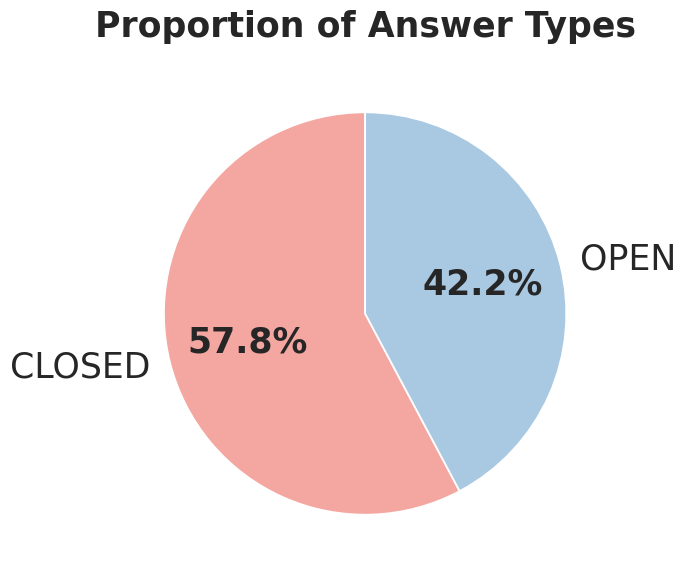

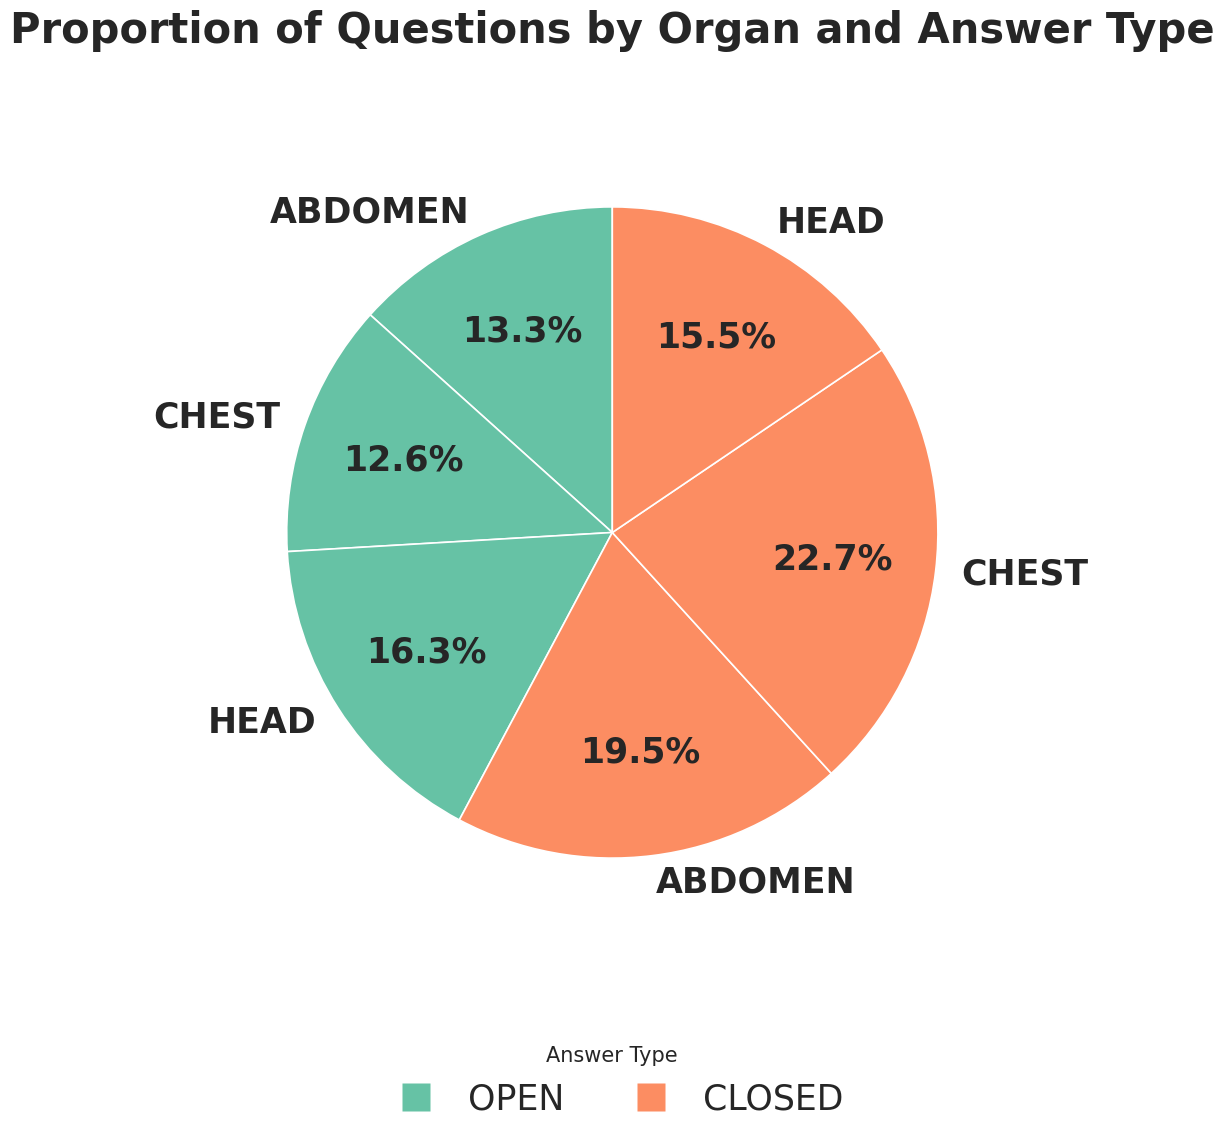

In [8]:
# =============================================================================
# INDIVIDUAL FIGURES FOR THE VQA-RAD DATASET
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.lines import Line2D


# =============================================================================
# 1. DATA PREPARATION
# =============================================================================

# Calculate lengths in words
df['question_words'] = (
    df['question']
    .fillna('')
    .astype(str)
    .str.split()
    .str.len()
)

df['answer_words'] = (
    df['answer']
    .fillna('')
    .astype(str)
    .str.split()
    .str.len()
)

# Normalize answer types
answer_type_clean = (
    df['answer_type']
    .fillna('UNKNOWN')
    .astype(str)
    .str.strip()
    .str.upper()
)

# Normalize organs
organ_clean = (
    df['image_organ']
    .fillna('UNKNOWN')
    .astype(str)
    .str.strip()
    .str.upper()
    .replace({
        'ABD': 'ABDOMEN'
    })
)

# Normalize question types
question_type_clean = (
    df['question_type']
    .fillna('UNKNOWN')
    .astype(str)
    .str.strip()
    .str.upper()
    .str.split(r'[/,;|]')
    .str[0]
    .str.strip()
    .replace({
        'PRSE': 'PRESENCE',
        'PRES': 'PRESENCE',
        'ATRIB': 'ATTRIBUTE',
        'ATTRIB': 'ATTRIBUTE',
        'ABN': 'ABNORMALITY',
        'POS': 'POSITION'
    })
)


# =============================================================================
# 2. GENERAL VISUAL CONFIGURATION
# =============================================================================

sns.set_theme(style='whitegrid')

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 15,
    'axes.titlesize': 19,
    'axes.titleweight': 'bold',
    'axes.labelsize': 17,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 13,
    'legend.title_fontsize': 14
})


# =============================================================================
# FIGURE 1. PROPORTION OF ANSWER TYPES
# =============================================================================

answer_types_dist = answer_type_clean.value_counts()

answer_type_colors = {
    'CLOSED': '#F4A6A1',
    'OPEN': '#A9C8E2'
}

colors_answer = [
    answer_type_colors.get(category, '#C7C7C7')
    for category in answer_types_dist.index
]

fig, ax = plt.subplots(figsize=(7, 6))

wedges, labels, percentages = ax.pie(
    answer_types_dist.values,
    labels=answer_types_dist.index,
    autopct='%1.1f%%',
    colors=colors_answer,
    startangle=90,
    textprops={
        'fontsize': 25
    },
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1.3
    }
)

for percentage in percentages:
    percentage.set_fontsize(25)
    percentage.set_fontweight('bold')

ax.set_title(
    'Proportion of Answer Types',
    fontsize=25,
    fontweight='bold',
    pad=18
)

plt.tight_layout()
plt.show()


# =============================================================================
# FIGURE 2. PROPORTION BY ORGAN AND ANSWER TYPE
# =============================================================================

# =============================================================================
# PROPORTION OF QUESTIONS BY ORGAN AND ANSWER TYPE
# Legend placed below to avoid overlapping labels
# =============================================================================

from matplotlib.lines import Line2D

# Prepare the data
df_organ_answer = pd.DataFrame({
    'Organ': (
        df['image_organ']
        .fillna('UNKNOWN')
        .astype(str)
        .str.strip()
        .str.upper()
        .replace({'ABD': 'ABDOMEN'})
    ),
    'Answer Type': (
        df['answer_type']
        .fillna('UNKNOWN')
        .astype(str)
        .str.strip()
        .str.upper()
    )
})

organ_answer_counts = (
    df_organ_answer
    .groupby(['Answer Type', 'Organ'])
    .size()
    .reset_index(name='Count')
)

# Order of answer types
answer_order = {
    'OPEN': 0,
    'CLOSED': 1
}

organ_answer_counts['Order'] = (
    organ_answer_counts['Answer Type']
    .map(answer_order)
    .fillna(99)
)

organ_answer_counts = organ_answer_counts.sort_values(
    ['Order', 'Organ']
)

values = organ_answer_counts['Count'].to_numpy()
organ_labels = organ_answer_counts['Organ'].tolist()
answer_types = organ_answer_counts['Answer Type'].tolist()

# Consistent colors
answer_colors = {
    'OPEN': '#66C2A5',
    'CLOSED': '#FC8D62'
}

wedge_colors = [
    answer_colors.get(answer_type, '#C7C7C7')
    for answer_type in answer_types
]

# Create the figure with bottom space for the legend
fig, ax = plt.subplots(figsize=(12, 12.5))

wedges, labels, percentages = ax.pie(
    values,
    labels=organ_labels,
    autopct=lambda percentage:
        f'{percentage:.1f}%' if percentage >= 2 else '',
    startangle=90,
    labeldistance=1.08,
    pctdistance=0.68,
    colors=wedge_colors,
    radius=0.88,
    textprops={
        'fontsize': 25
    },
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1.2
    }
)

# Format organ labels
for label in labels:
    label.set_fontsize(25)
    label.set_fontweight('bold')

# Format percentages
for percentage in percentages:
    percentage.set_fontsize(25)
    percentage.set_fontweight('bold')

# Create horizontal legend
legend_types = [
    answer_type
    for answer_type in ['OPEN', 'CLOSED']
    if answer_type in answer_types
]

legend_handles = [
    Line2D(
        [0],
        [0],
        marker='s',
        linestyle='',
        markerfacecolor=answer_colors[answer_type],
        markeredgecolor='none',
        markersize=20
    )
    for answer_type in legend_types
]

ax.legend(
    legend_handles,
    legend_types,
    title='Answer Type',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
    fontsize=25,
    title_fontsize=15,
    handletextpad=0.5,
    columnspacing=1.5
)

ax.set_title(
    'Proportion of Questions by Organ and Answer Type',
    fontsize=30,
    fontweight='bold',
    pad=20
)

ax.set_aspect('equal')

plt.subplots_adjust(
    top=0.90,
    bottom=0.16,
    left=0.08,
    right=0.92
)

plt.show()


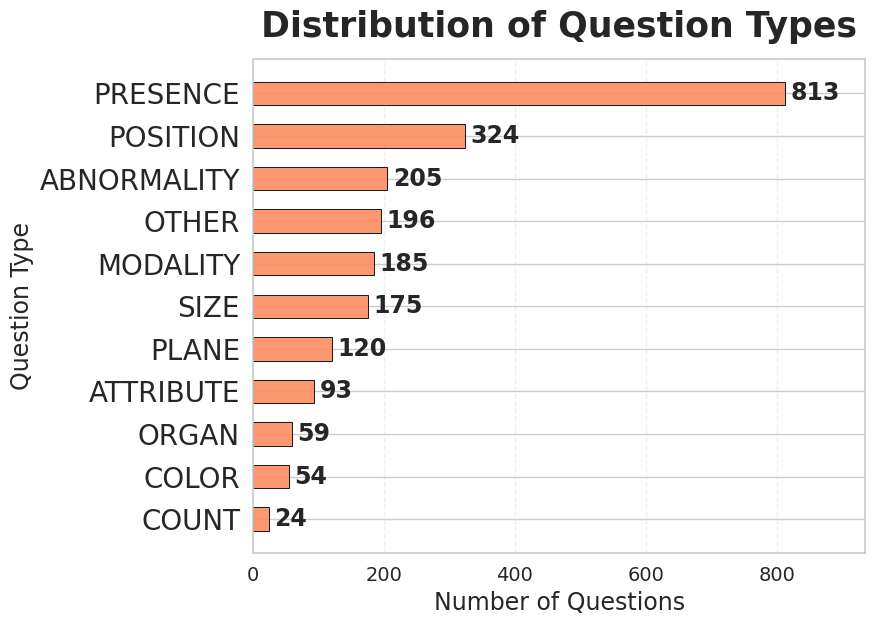

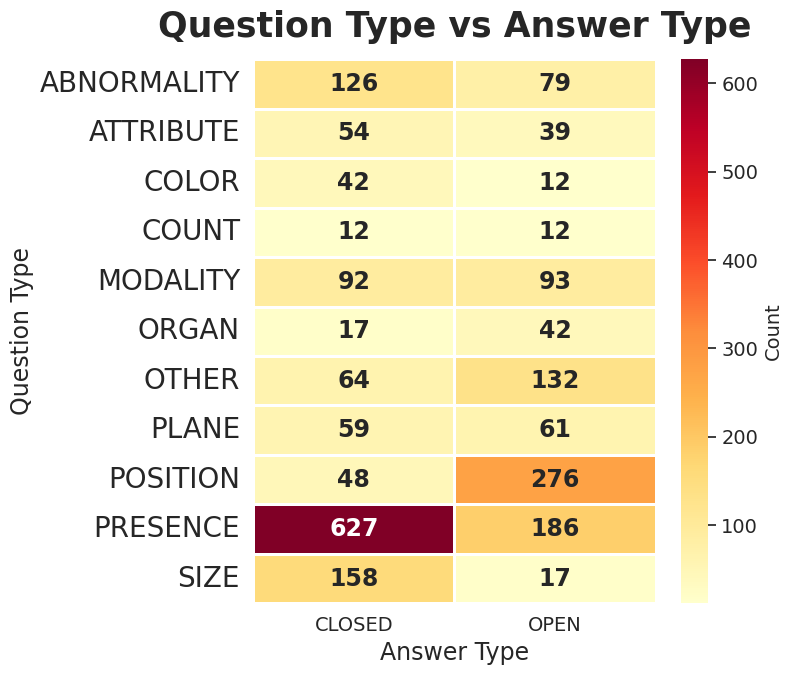

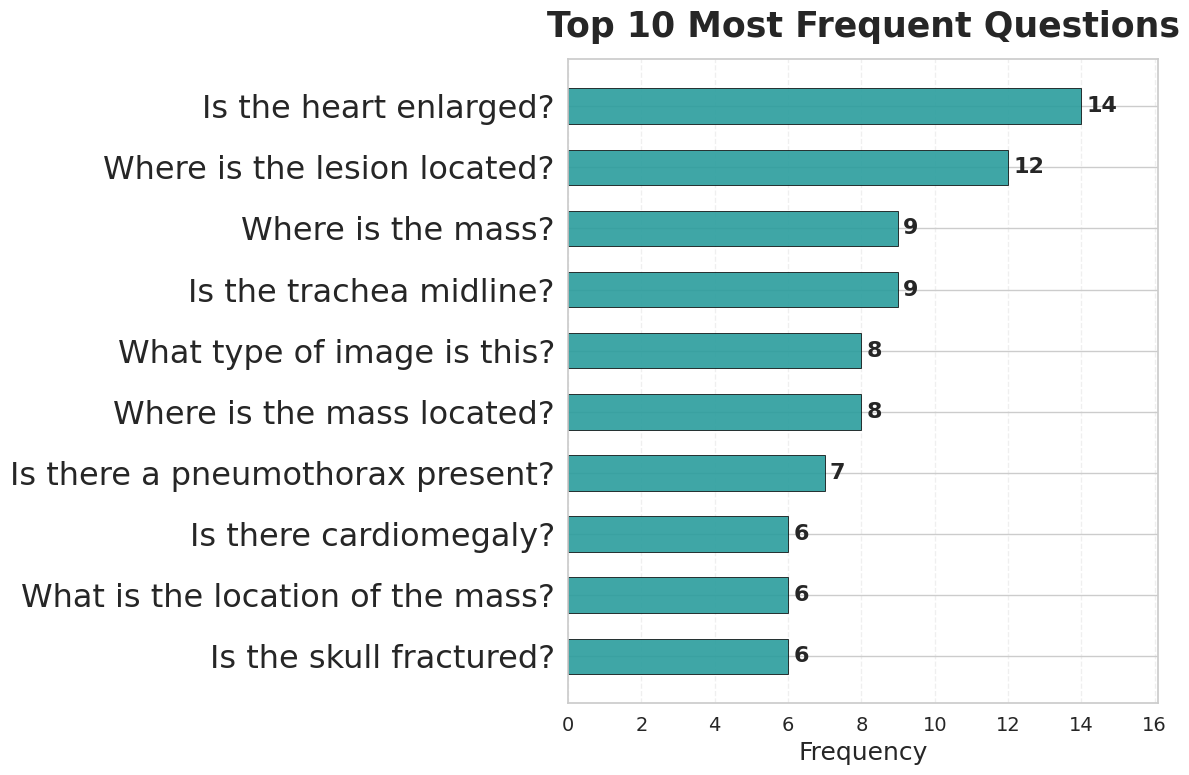

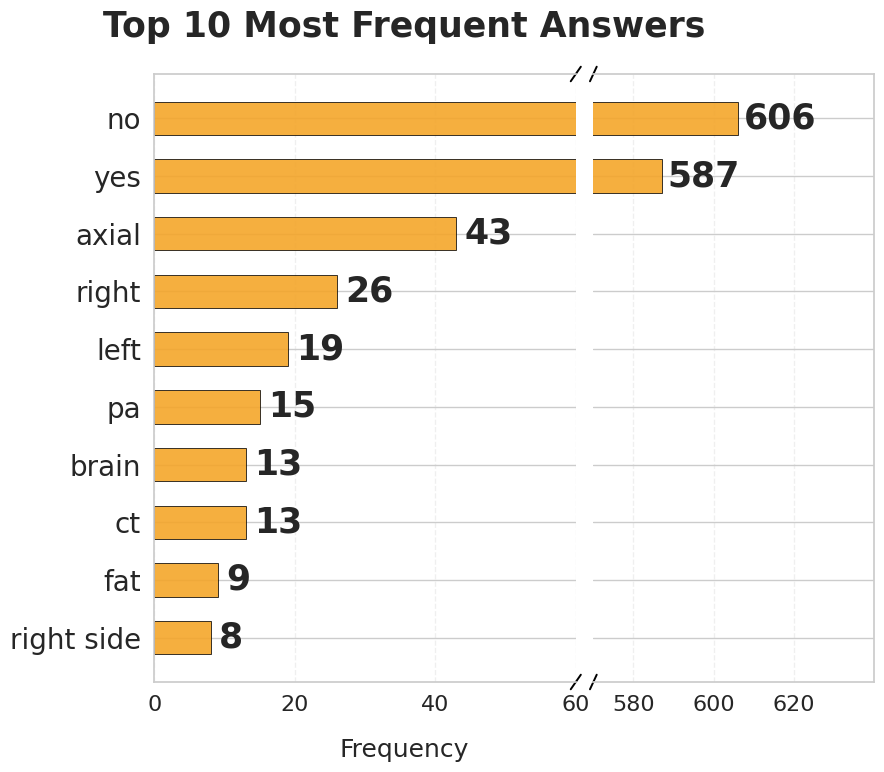

In [9]:
# =============================================================================
# FIGURE 3. DISTRIBUTION OF QUESTION TYPES
# =============================================================================

question_type_counts = (
    question_type_clean
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6.5))

bars = ax.barh(
    np.arange(len(question_type_counts)),
    question_type_counts.values,
    height=0.55,
    color='#FC8D62',
    edgecolor='black',
    linewidth=0.7,
    alpha=0.9
)

ax.set_yticks(np.arange(len(question_type_counts)))
ax.set_yticklabels(
    question_type_counts.index,
    fontsize=20
)

ax.set_xlabel(
    'Number of Questions',
    fontsize=17
)

ax.set_ylabel(
    'Question Type',
    fontsize=17
)

ax.set_title(
    'Distribution of Question Types',
    fontsize=25,
    fontweight='bold',
    pad=16
)

ax.set_xlim(
    0,
    question_type_counts.max() * 1.15
)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

ax.set_axisbelow(True)

for bar, value in zip(bars, question_type_counts.values):
    ax.text(
        value + question_type_counts.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va='center',
        ha='left',
        fontsize=17,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


# =============================================================================
# FIGURE 4. QUESTION TYPE VS. ANSWER TYPE
# =============================================================================

question_answer_cross = pd.crosstab(
    question_type_clean,
    answer_type_clean
)

fig, ax = plt.subplots(figsize=(8, 7))

heatmap = sns.heatmap(
    question_answer_cross,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.8,
    linecolor='white',
    annot_kws={
        'size': 17,
        'weight': 'bold'
    },
    cbar_kws={
        'label': 'Count'
    },
    ax=ax
)

ax.set_xlabel(
    'Answer Type',
    fontsize=17
)

ax.set_ylabel(
    'Question Type',
    fontsize=17
)

ax.set_title(
    'Question Type vs Answer Type',
    fontsize=25,
    fontweight='bold',
    pad=16
)

ax.tick_params(
    axis='x',
    labelsize=14,
    rotation=0
)

ax.tick_params(
    axis='y',
    labelsize=20,
    rotation=0
)

colorbar = heatmap.collections[0].colorbar
colorbar.ax.tick_params(labelsize=14)
colorbar.set_label('Count', fontsize=14)

plt.tight_layout()
plt.show()


# =============================================================================
# FIGURE 5. TOP 10 MOST FREQUENT QUESTIONS
# =============================================================================

top_questions = (
    df['question']
    .fillna('')
    .astype(str)
    .value_counts()
    .head(10)
    .sort_values()
)

question_labels = [
    question[:60] + '...' if len(question) > 60 else question
    for question in top_questions.index
]

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    np.arange(len(top_questions)),
    top_questions.values,
    height=0.58,
    color='#2A9D9D',
    edgecolor='black',
    linewidth=0.6,
    alpha=0.9
)

ax.set_yticks(np.arange(len(top_questions)))
ax.set_yticklabels(
    question_labels,
    fontsize=23
)

ax.set_xlabel(
    'Frequency',
    fontsize=18
)

ax.set_title(
    'Top 10 Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    pad=16
)

ax.set_xlim(
    0,
    top_questions.max() * 1.15
)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

ax.set_axisbelow(True)

for bar, value in zip(bars, top_questions.values):
    ax.text(
        value + top_questions.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va='center',
        ha='left',
        fontsize=16,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


# =============================================================================
# FIGURE 6. TOP 10 MOST FREQUENT ANSWERS
# =============================================================================

# Top 10 most frequent answers
top_answers = df['answer'].value_counts().head(10)

# Answers labels
answer_labels = [
    answer[:50] + '...' if len(answer) > 50 else answer for answer in top_answers.index
]

positions = np.arange(len(top_answers))

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(10, 8),
    gridspec_kw={
        'width_ratios': [2.7, 1.8],
        'wspace': 0.05
    }
)

axes = (ax1, ax2)

# Draw the bars in both segments
for ax in axes:
    ax.barh(
        positions,
        top_answers.values,
        height=0.58,
        color='#F4A62A',
        edgecolor='black',
        linewidth=0.6,
        alpha=0.9
    )

    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.3
    )

    ax.set_axisbelow(True)
    ax.tick_params(axis='x', labelsize=16)

# Limits before and after the break
ax1.set_xlim(0, 60)
ax2.set_xlim(570, 640)

ax1.set_xticks([0, 20, 40, 60])
ax2.set_xticks([580, 600, 620])

# Y-axis labels
ax1.set_yticks(positions)

ax1.set_yticklabels(
    answer_labels,
    fontsize=20
)

ax1.invert_yaxis()

# Hide repeated labels
ax2.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Hide interior borders
ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)

# Diagonal break marks
d = 0.012

break_kwargs = dict(
    color='black',
    clip_on=False,
    linewidth=1.4
)

ax1.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax1.transAxes,
    **break_kwargs
)

ax1.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax1.transAxes,
    **break_kwargs
)

ax2.plot(
    (-d, +d),
    (-d, +d),
    transform=ax2.transAxes,
    **break_kwargs
)

ax2.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **break_kwargs
)

# Place each frequency in its corresponding segment
for position, value in zip(
    positions,
    top_answers.values
):
    if value <= 60:
        axis = ax1
        offset = 1.2
    else:
        axis = ax2
        offset = 1.5

    axis.text(
        value + offset,
        position,
        f'{value:,}',
        va='center',
        ha='left',
        fontsize=25,
        fontweight='bold'
    )

# Shared title and X label
fig.suptitle(
    'Top 10 Most Frequent Answers',
    fontsize=25,
    fontweight='bold',
    y=0.98
)

fig.supxlabel(
    'Frequency',
    fontsize=18,
    y=0.04
)

plt.subplots_adjust(
    left=0.25,
    right=0.97,
    top=0.90,
    bottom=0.14
)

plt.show()

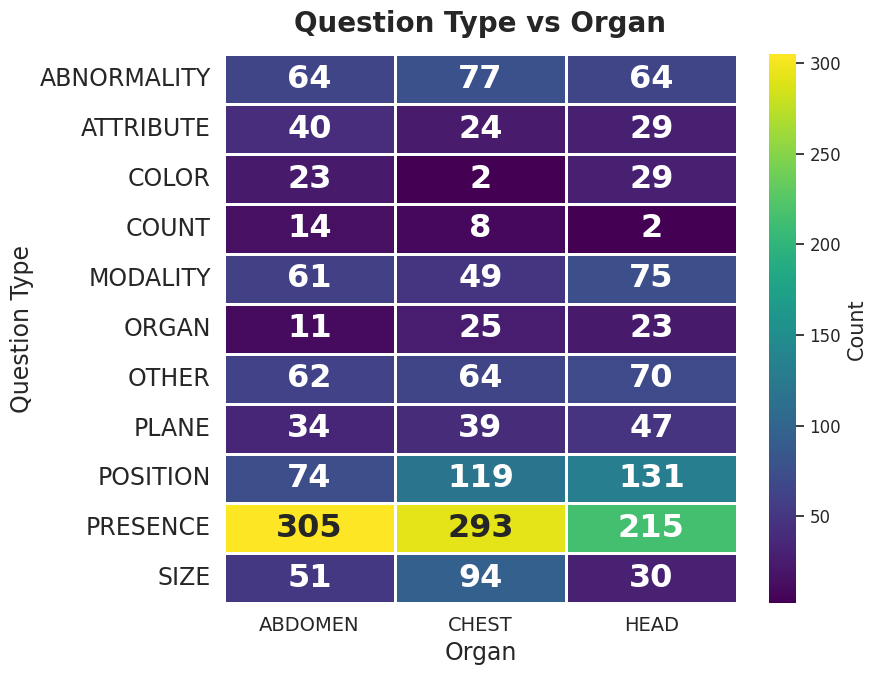

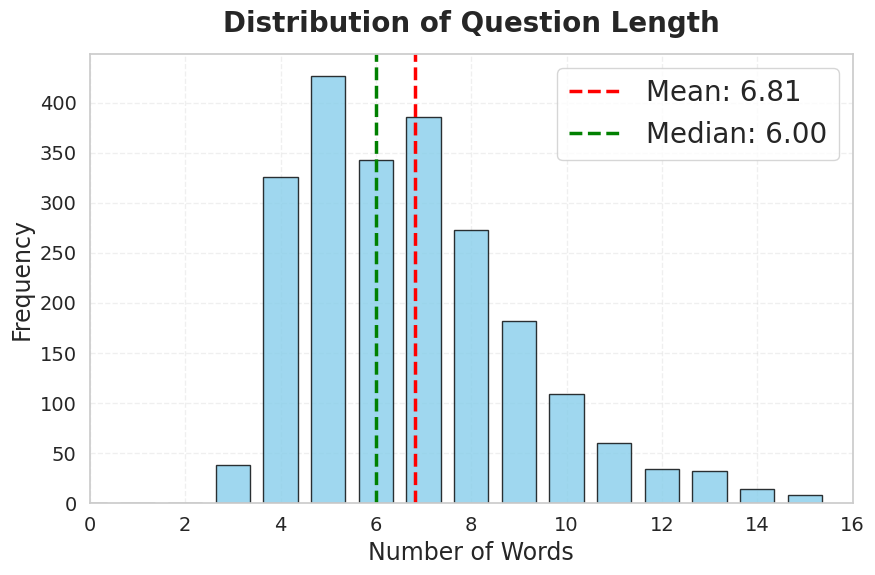

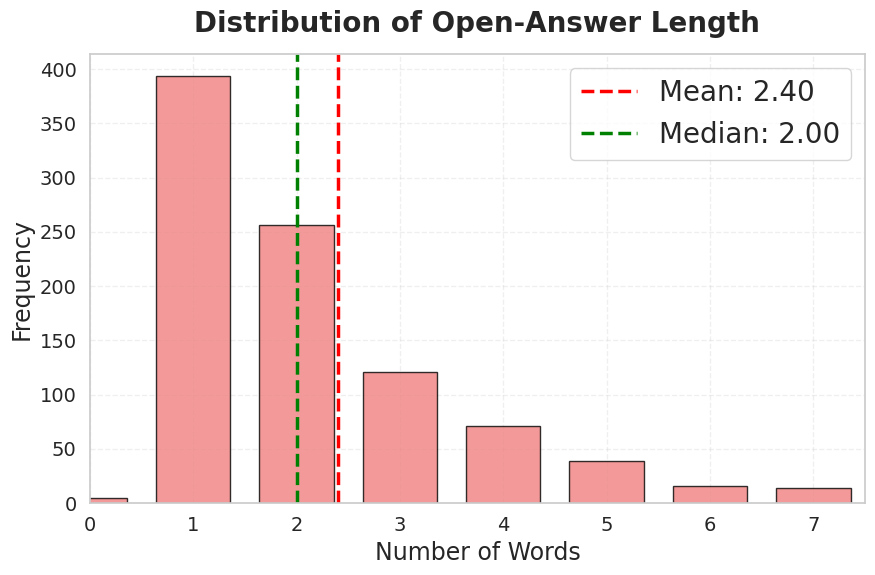

In [10]:
# =============================================================================
# FIGURE 7. QUESTION TYPE VS. ORGAN
# =============================================================================

question_organ_cross = pd.crosstab(
    question_type_clean,
    organ_clean
)

# Sort the organs
preferred_organ_order = [
    organ
    for organ in ['ABDOMEN', 'CHEST', 'HEAD']
    if organ in question_organ_cross.columns
]

remaining_organs = [
    organ
    for organ in question_organ_cross.columns
    if organ not in preferred_organ_order
]

question_organ_cross = question_organ_cross[
    preferred_organ_order + remaining_organs
]

fig, ax = plt.subplots(figsize=(9, 7))

heatmap = sns.heatmap(
    question_organ_cross,
    annot=True,
    fmt='d',
    cmap='viridis',
    linewidths=0.8,
    linecolor='white',
    annot_kws={
        'size': 23,
        'weight': 'bold'
    },
    cbar_kws={
        'label': 'Count'
    },
    ax=ax
)

ax.set_xlabel(
    'Organ',
    fontsize=17
)

ax.set_ylabel(
    'Question Type',
    fontsize=17
)

ax.set_title(
    'Question Type vs Organ',
    fontsize=20,
    fontweight='bold',
    pad=16
)

ax.tick_params(
    axis='x',
    labelsize=14,
    rotation=0
)

ax.tick_params(
    axis='y',
    labelsize=17,
    rotation=0
)

colorbar = heatmap.collections[0].colorbar
colorbar.ax.tick_params(labelsize=12)
colorbar.set_label('Count', fontsize=15)

plt.tight_layout()
plt.show()


# =============================================================================
# FIGURE 8. DISTRIBUTION OF QUESTION LENGTH
# =============================================================================

question_mean = df['question_words'].mean()
question_median = df['question_words'].median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df['question_words'],
    bins=np.arange(-0.5, 16.5, 1),
    color='#87CEEB',
    edgecolor='black',
    linewidth=1,
    alpha=0.80,
    rwidth=0.72
)

ax.axvline(
    question_mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {question_mean:.2f}'
)

ax.axvline(
    question_median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {question_median:.2f}'
)

ax.set_xlim(0, 16)

ax.set_xlabel(
    'Number of Words',
    fontsize=17
)

ax.set_ylabel(
    'Frequency',
    fontsize=17
)

ax.set_title(
    'Distribution of Question Length',
    fontsize=20,
    fontweight='bold',
    pad=16
)

ax.legend(
    fontsize=20,
    loc='upper right'
)

ax.grid(
    linestyle='--',
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# =============================================================================
# FIGURE 9. DISTRIBUTION OF OPEN-ANSWER LENGTH
# =============================================================================

open_answer_words = df.loc[
    answer_type_clean == 'OPEN',
    'answer_words'
].dropna()

answer_mean = open_answer_words.mean()
answer_median = open_answer_words.median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    open_answer_words,
    bins=np.arange(-0.5, 8.5, 1),
    color='#F08080',
    edgecolor='black',
    linewidth=1,
    alpha=0.80,
    rwidth=0.72
)

ax.axvline(
    answer_mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {answer_mean:.2f}'
)

ax.axvline(
    answer_median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {answer_median:.2f}'
)

ax.set_xlim(0, 7.5)

ax.set_xlabel(
    'Number of Words',
    fontsize=17
)

ax.set_ylabel(
    'Frequency',
    fontsize=17
)

ax.set_title(
    'Distribution of Open-Answer Length',
    fontsize=20,
    fontweight='bold',
    pad=16
)

ax.legend(
    fontsize=20,
    loc='upper right'
)

ax.grid(
    linestyle='--',
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()